# Cost-Sensitive Decision-Making for Credit Card Default

## Table of Contents

- [1. Introduction](#1.-Introduction)
- [2. Setup](#2.-Setup)
  - [2.1. Imports and Configuration](#2.1.-Imports-and-Configuration)
- [3. Data Loading and Description](#3.-Data-Loading-and-Description)
  - [3.1. Data Loading](#3.1.-Data-Loading)
  - [3.2. Variable Definitions](#3.2.-Variable-Definitions)
  - [3.3. Missing Values](#3.3.-Missing-Values)
- [4. Train-Test Split](#4.-Train-Test-Split)
- [5. Exploratory Data Analysis](#5.-Exploratory-Data-Analysis)
  - [5.1. Descriptive Statistics](#5.1.-Descriptive-Statistics)
  - [5.2. Skewness of Numerical Features](#5.2.-Skewness-of-Numerical-Features)
  - [5.3. Payment Amount Distributions](#5.3.-Payment-Amount-Distributions)
  - [5.4. Bill Amount Distributions](#5.4.-Bill-Amount-Distributions)
  - [5.5. Education](#5.5.-Education)
  - [5.6. Marital Status](#5.6.-Marital-Status)
  - [5.7. Repayment Status](#5.7.-Repayment-Status)
  - [5.8. Target Distribution](#5.8.-Target-Distribution)
  - [5.9. Correlation Analysis of Original Features](#5.9.-Correlation-Analysis-of-Original-Features)
- [6. Feature Engineering](#6.-Feature-Engineering)
  - [6.1. Removing Linearly Dependent Features](#6.1.-Removing-Linearly-Dependent-Features)
- [7. L1 Regularization and Feature Selection](#7.-L1-Regularization-and-Feature-Selection)
  - [7.1. Regularization Path](#7.1.-Regularization-Path)
    - [Absolute Coefficient Values](#Absolute-Coefficient-Values)
    - [Number of Non-Zero Coefficients](#Number-of-Non-Zero-Coefficients)
  - [Selecting C Values for Cross-Validation](#Selecting-C-Values-for-Cross-Validation)
  - [Repeated Stratified Cross-Validation](#Repeated-Stratified-Cross-Validation)
  - [Selecting C Based on Mean Validation ROC AUC](#Selecting-C-Based-on-Mean-Validation-ROC-AUC)
  - [Baseline Model](#Baseline-Model)
  - [Model Performance Comparison](#Model-Performance-Comparison)
  - [Performance Comparison Across Folds](#Performance-Comparison-Across-Folds)
- [Gradient Boosting Model](#Gradient-Boosting-Model)
  - [Comparing Gradient Boosting Settings](#Comparing-Gradient-Boosting-Settings)
  - [Training and Validation Loss](#Training-and-Validation-Loss)
  - [Comparing Selected Models Across Folds](#Comparing-Selected-Models-Across-Folds)
- [Final Test Evaluation](#Final-Test-Evaluation)
- [Cost-Based Threshold Selection](#Cost-Based-Threshold-Selection)
  - [Prediction Outcomes Across Thresholds](#Prediction-Outcomes-Across-Thresholds)
  - [Cost Calculation and Threshold Selection](#Cost-Calculation-and-Threshold-Selection)
- [Bootstrap Uncertainty Estimates](#Bootstrap-Uncertainty-Estimates)
- [Conclusion](#Conclusion)

## 1. Introduction



This project uses the *Default of Credit Card Clients* dataset from the UCI Machine Learning Repository, containing demographic information, credit limits, and payment histories for credit card clients in Taiwan. The target indicates whether a client defaults on their payment in the following month.

The central question is how predicted default risk can support a decision about whether to take preventive action. Flagging a client who would not default may lead to unnecessary intervention costs, while failing to flag a client who defaults may leave the bank exposed to losses. These two types of error—false positives and false negatives—can have different financial consequences.

Since the dataset does not specify the costs of unnecessary preventive action or of failing to act when needed, this project determines the decision threshold as a function of their assumed cost ratio. Predictive models are developed and evaluated to estimate default risk. Clients are then flagged for preventive action when their predicted risk exceeds the threshold that minimizes the combined cost of false positives and false negatives for the chosen cost ratio.


## 2. Setup

### 2.1. Imports and Configuration

In [5]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, RepeatedStratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score, precision_score, average_precision_score, f1_score, roc_auc_score, brier_score_loss
from sklearn.metrics import roc_curve, precision_recall_curve, confusion_matrix, log_loss
from sklearn.svm import l1_min_c
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.utils import resample
import seaborn as sns
from scipy.stats import ttest_1samp
from matplotlib import pyplot as plt
from pathlib import Path

# Configuration

# True: load saved training results when available; otherwise, run training.
# False: rerun training regardless of existing result files.
LOAD_TRAIN_RESULTS = True

# True: overwrite existing training result files when saving.
# False: preserve existing files.
OVERWRITE_FILE = True

## 3. Data Loading and Description

### 3.1. Data Loading

In [7]:
data_path = Path('../Data/default of credit card clients.xls')
df = pd.read_excel(
    data_path,
    header=1,
    index_col=0
)
print(f'Dataset shape: {df.shape}')
df.head()

Dataset shape: (30000, 24)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
ID,,,,,,,,,,,,,,,,,,,,,
1,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
2,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
3,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
4,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
5,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


### 3.2. Variable Definitions

The variables are described below based on the [official UCI dataset documentation](https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients).

* **`LIMIT_BAL`**: Total granted credit limit in New Taiwan dollars (NT$), including individual and supplementary/family credit.

* **`SEX`**: Client gender (`1` = male, `2` = female).

* **`EDUCATION`**: Education level (`1` = graduate school, `2` = university, `3` = high school, `4` = other).

* **`MARRIAGE`**: Marital status (`1` = married, `2` = single, `3` = other).

* **`AGE`**: Client age in years.

* **`PAY_0`, `PAY_2`–`PAY_6`**: Monthly repayment status from September to April 2005. According to the dataset documentation, `-1` indicates payment made duly, while positive values indicate the number of months of payment delay (`1` = one month, ..., `9` = nine months or more).

* **`BILL_AMT1`–`BILL_AMT6`**: Monthly bill statement amounts from September to April 2005, measured in NT$.

* **`PAY_AMT1`–`PAY_AMT6`**: Monthly payment amounts from September to April 2005, measured in NT$.

* **`default payment next month`**: Binary target variable (`1` = default, `0` = no default).

The numbered monthly features follow reverse chronological order: suffix `1` represents September 2005 and suffix `6` represents April 2005. `PAY_*` variables describe repayment **status**, whereas `PAY_AMT*` variables describe actual **payment amounts**.


### 3.3. Missing Values

Missing values are checked across the entire dataset.

In [10]:
print('Missing values per column:')
df.isna().sum()

Missing values per column:


LIMIT_BAL                     0
SEX                           0
EDUCATION                     0
MARRIAGE                      0
AGE                           0
PAY_0                         0
PAY_2                         0
PAY_3                         0
PAY_4                         0
PAY_5                         0
PAY_6                         0
BILL_AMT1                     0
BILL_AMT2                     0
BILL_AMT3                     0
BILL_AMT4                     0
BILL_AMT5                     0
BILL_AMT6                     0
PAY_AMT1                      0
PAY_AMT2                      0
PAY_AMT3                      0
PAY_AMT4                      0
PAY_AMT5                      0
PAY_AMT6                      0
default payment next month    0
dtype: int64

No missing values were found in the data, therefore no missing-value imputation is required.

## 4. Train-Test Split

The dataset is split into training and test sets using an 80/20 ratio. The training set is used for model development, feature comparison, and cross-validation, while the test set is kept separate for the final evaluation of the selected models.

In [13]:
X = df.drop(columns='default payment next month').copy()
y = df['default payment next month'].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,y,
    random_state = 42,
    test_size = 0.2,
    stratify = y    
)

## 5. Exploratory Data Analysis
### 5.1. Descriptive Statistics

In [15]:
X_train.describe().T

,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,24000.0,167364.666667,129511.313151,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,24000.0,1.604750,0.488915,1.0,1.00,2.0,2.00,2.0
EDUCATION,24000.0,1.853792,0.792375,0.0,1.00,2.0,2.00,6.0
MARRIAGE,24000.0,1.552875,0.521903,0.0,1.00,2.0,2.00,3.0
AGE,24000.0,35.432625,9.195256,21.0,28.00,34.0,41.00,75.0
PAY_0,24000.0,-0.014125,1.123155,-2.0,-1.00,0.0,0.00,8.0
PAY_2,24000.0,-0.134083,1.198818,-2.0,-1.00,0.0,0.00,8.0
PAY_3,24000.0,-0.166917,1.194166,-2.0,-1.00,0.0,0.00,8.0
PAY_4,24000.0,-0.221333,1.161924,-2.0,-1.00,0.0,0.00,8.0
PAY_5,24000.0,-0.270333,1.125192,-2.0,-1.00,0.0,0.00,8.0


* `LIMIT_BAL`, `BILL_AMT*`, and `PAY_AMT*` have maximum values substantially above their 75th percentiles, indicating that some observations are much larger than most values in these features.

* `EDUCATION` includes values outside the documented range of 1–4, while `MARRIAGE` includes 0, which is not defined in the dataset documentation. 

* `PAY_*` features include values of -2 and 0, whose meanings are not specified in the cited documentation.

* `AGE` ranges from 21 to 75 years, which is a plausible range for credit card clients.

The following distribution plots and category counts provide a more detailed view of these features.

### 5.2. Skewness of Numerical Features

Skewness is calculated for numerical features to assess distribution asymmetry. Positive values indicate right skewness, while negative values indicate left skewness. Values close to zero suggest approximate symmetry. Categorical codes are excluded from this analysis.

In [18]:
numerical_features = [
    'LIMIT_BAL', 'AGE',
    *[f'BILL_AMT{i}' for i in range(1,7)],
    *[f'PAY_AMT{i}' for i in range(1,7)]
]

X_train[numerical_features].skew().to_frame(
    name='Skewness'
).sort_values(
    by='Skewness',
    ascending=False
)


,Skewness
PAY_AMT2,21.124266
PAY_AMT3,18.637888
PAY_AMT1,15.312137
PAY_AMT4,12.376313
PAY_AMT5,11.131497
PAY_AMT6,10.549438
BILL_AMT5,2.919957
BILL_AMT6,2.882477
BILL_AMT4,2.822983
BILL_AMT3,2.729105


PAY_AMT features are extremely right skewed and BILL_AMT features are also strongly right skewed. Their distributions require further investigation.

### 5.3. Payment Amount Distributions

The `PAY_AMT*` features are strongly right-skewed. A log1p transformation, log(1 + x), is used for visualization to accommodate zero payments and make the distributions easier to inspect.

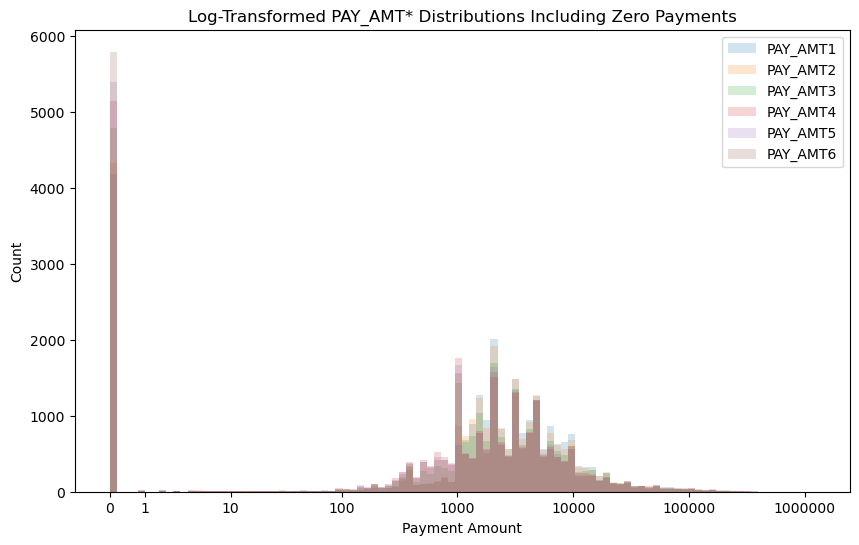

In [21]:
plt.figure(figsize=(10,6))

max_value_pay = X_train[
    [f'PAY_AMT{i}' for i in range(1,7)]
].max().max()

bins_pay_amt = np.linspace(
    0,
    np.log1p(max_value_pay),
    101
)

for i in range(1,7):
    plt.hist(
        np.log1p(
            X_train[f'PAY_AMT{i}']
        ),
        label=f'PAY_AMT{i}',
        bins=bins_pay_amt,
        alpha=0.2
    )

ticks_original = [0] + [10**i for i in range(7)]

plt.xticks(
    np.log1p(ticks_original),
    ticks_original
)

plt.legend()
plt.xlabel('Payment Amount')
plt.ylabel('Count')
plt.title('Log-Transformed PAY_AMT* Distributions Including Zero Payments')
plt.show()

All six payment features show a pronounced spike at zero, representing observations with no recorded payment in the corresponding month. These high counts compress the visual detail of the positive payment distributions. A second plot therefore displays only positive payments, while retaining all observations in the dataset used for modeling.

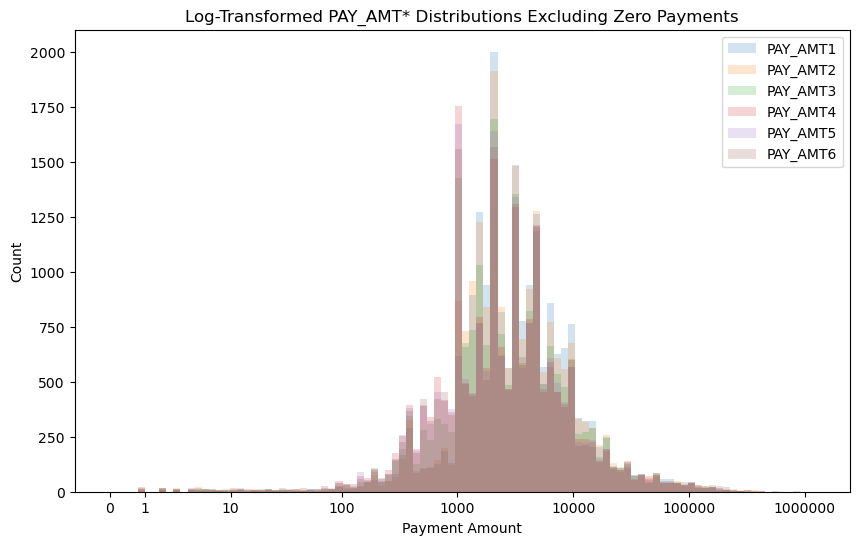

In [23]:
plt.figure(figsize=(10,6))
for i in range(1,7):
    plt.hist(
        np.log1p(
            X_train[f'PAY_AMT{i}'][X_train[f'PAY_AMT{i}'] > 0]
        ),
        label=f'PAY_AMT{i}',
        bins=bins_pay_amt,
        alpha=0.2
    )

    plt.xticks(
        np.log1p(ticks_original),
        ticks_original
    )
    
plt.xlabel('Payment Amount')
plt.ylabel('Count')
plt.legend()
plt.title('Log-Transformed PAY_AMT* Distributions Excluding Zero Payments')
plt.show()

The `PAY_AMT*` features are strongly right-skewed and contain a small number of extremely large values. A log transformation could reduce the skewness and decrease the influence of these extreme values. Therefore, log-transformed payment amounts will be considered as an alternative representation during feature engineering.

### 5.4. Bill Amount Distributions

The `BILL_AMT*` features are strongly right-skewed. The plots below provide a closer look at their distributions.

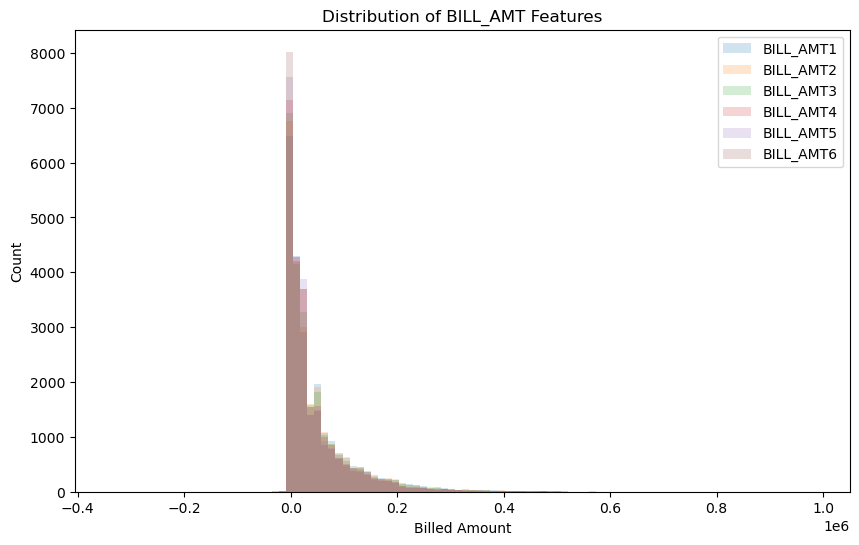

Proportion of negative values:2.16%


In [26]:
bill_amt_max = X_train[[f'BILL_AMT{i}' for i in range(1,7)]].max().max() + 1
bill_amt_min = X_train[[f'BILL_AMT{i}' for i in range(1,7)]].min().min() - 1
bill_amt_range = bill_amt_max - bill_amt_min

bins_bill_amt = [bill_amt_min + (i * bill_amt_range/100)  for i in range(101)]

plt.figure(figsize=(10,6))
for i in range(1,7):
    plt.hist(
        X_train[f'BILL_AMT{i}'],
        label=f'BILL_AMT{i}',
        alpha=0.2,
        bins = bins_bill_amt
    )

plt.xlabel('Billed Amount')
plt.ylabel('Count')
plt.title('Distribution of BILL_AMT Features')
plt.legend()
plt.show()

print(f"Proportion of negative values:{100 * (X_train[[f'BILL_AMT{i}' for i in range(1,7)]] < 0).sum().sum()/(len(X_train)*6):.2f}%")

Negative values account for 2.16% of all statement amounts across the six `BILL_AMT*` features in the training set. These may represent credit balances resulting from overpayments, refunds, or other adjustments, although their meaning is not clarified in the UCI documentation. Negative values are retained, as their sign alone does not establish that they are data errors.

### 5.5. Education

Category counts are examined to identify the most common education levels and any undocumented codes in `EDUCATION`.

In [29]:
X_train['EDUCATION'].value_counts().sort_index(ascending=False)

EDUCATION
6       42
5      235
4       97
3     3903
2    11256
1     8455
0       12
Name: count, dtype: int64

`EDUCATION` includes the undocumented values 0, 5, and 6. These are retained as distinct categories. The variable will be one-hot encoded, with category 0 used as the reference category.

### 5.6. Marital Status

Category counts are examined to understand the distribution of `MARRIAGE` and identify undocumented codes.

In [32]:
X_train['MARRIAGE'].value_counts().sort_index(ascending=False)

MARRIAGE
3      255
2    12806
1    10892
0       47
Name: count, dtype: int64

`MARRIAGE` includes the undocumented category 0. Since its meaning is unknown, it is retained as a separate category. The variable will be one-hot encoded because the numerical category labels do not represent a linear relationship.

### 5.7. Repayment Status

The PAY_* features show repayment status for six consecutive months. Their values are combined here to count how often each category appears across the six months.

In [35]:
pay_category_counts = X_train[[f"PAY_{i}" for i in [0,2,3,4,5,6]]].stack().value_counts()

for idx in pay_category_counts.index.sort_values(ascending=False):
    print(f'Category:{idx:>3} - Count:{pay_category_counts.loc[idx]:>6}')   

Category:  8 - Count:    22
Category:  7 - Count:   157
Category:  6 - Count:    57
Category:  5 - Count:   104
Category:  4 - Count:   356
Category:  3 - Count:  1125
Category:  2 - Count: 15206
Category:  1 - Count:  3030
Category:  0 - Count: 76738
Category: -1 - Count: 27629
Category: -2 - Count: 19576


Contrary to the official dataset description, the `PAY_*` features also contain the categories 0 and -2, whose meanings are not defined in the documentation. The documented maximum category is 9, while the largest value observed in the training data is 8.

There are two possible ways to represent the repayment-status categories:

1. **Numerical representation:**
   `-1` can be mapped to 0 months of delay, while categories `1–9` can represent the corresponding number of delayed months. The undocumented categories `-2` and `0` would need to be represented separately.
   **Advantage:** simple representation with fewer features and it can naturally handle category 9 even though it is not present in the training data.
   **Disadvantage:** it assumes an approximately linear relationship between the length of the delay and its effect on default risk.

2. **One-hot encoding:**
   Each observed repayment category can be represented separately, allowing every category to have its own effect on the prediction. The undocumented categories `-2` and `0` can also be retained without assuming any relationship with the documented categories.
   **Advantage:** no linear relationship between repayment categories and default risk needs to be assumed.
   **Disadvantage:** it creates more features, and category 9 cannot have its own learned effect because it is missing from the training data. To handle this, category 8 can be defined as `8+`, representing delays of eight months or more.

The numerical representation is chosen to keep the model simpler and use fewer features. The undocumented codes -2 and 0 are represented by separate indicator variables.

### 5.8. Target Distribution

We examine the target distribution in the training set to check for class imbalance.

In [38]:
print(f'Default rate in the training set:{100 * y_train.mean():.2f}%')

Default rate in the training set:22.12%


Approximately 22% of clients in the training set defaulted, while 78% did not. A model that always predicts no default would therefore achieve about 78% accuracy. Therefore accuracy alone is not enough to evaluate model performance.

### 5.9. Correlation Analysis of Original Features

A Pearson correlation heatmap is used to examine linear relationships between features and with the target. `EDUCATION` and `MARRIAGE` are excluded because their category codes are not numerical measurements.

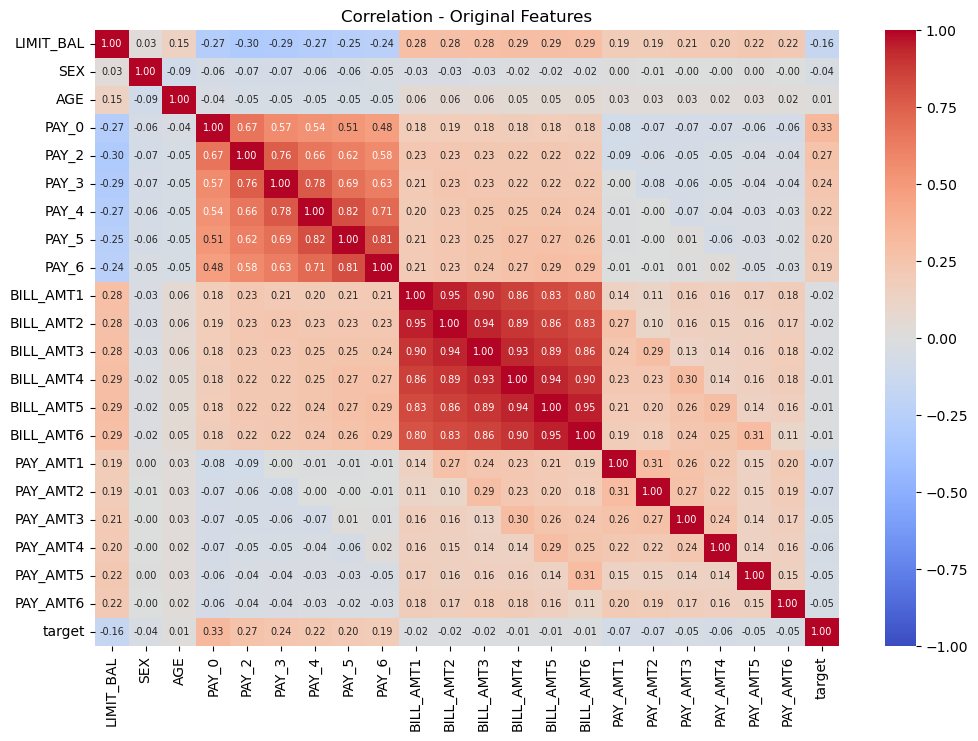

In [41]:
corr_data = X_train.drop(columns=['EDUCATION','MARRIAGE']).copy()
corr_data['target'] = y_train

plt.figure(figsize=(12,8))
plt.title('Correlation - Original Features')
sns.heatmap(
    corr_data[list(corr_data.columns)].corr(),
    annot = True,
    fmt='.2f',
    annot_kws={'fontsize': 7},
    center=0,
    vmin=-1,
    vmax=1,
    cmap='coolwarm'
)
plt.show()

`PAY_*` features are moderately to strongly correlated with each other and show the strongest positive correlation with the target. `PAY_0`, representing the most recent repayment status, has the highest correlation, while the correlation gradually decreases toward `PAY_6`. This suggests that recent repayment behavior may be more related to default risk.

`BILL_AMT*` features are strongly correlated with each other, suggesting that they contain similar information. Therefore, summary features such as the mean bill amount across the six months will also be tested.

`PAY_AMT*` features show weaker correlations with each other, while both `PAY_AMT*` and `BILL_AMT*` show only weak correlation with the target. Since the meaning of these absolute amounts may depend on the client's credit limit, credit-limit-scaled features will also be created and tested.

`LIMIT_BAL` shows a weak negative correlation with the target, suggesting that higher credit limits are associated with a lower chance of default in the training data.


## 6. Feature Engineering

Based on the data analysis, the following additional features and alternative representations will be created and tested:

* **Credit-limit-normalized features:** `PAY_LIMIT*` and `BILL_LIMIT*` divide payment and bill amounts by the credit limit to show their relative size.

$$
PAY\_LIMIT_i = \frac{PAY\_AMT_i}{LIMIT\_BAL}
$$

$$
BILL\_LIMIT_i = \frac{BILL\_AMT_i}{LIMIT\_BAL}
$$

* **Bill summary features:** `BILL_AMT_MEAN` gives the mean bill amount across the six months. `BILL_AMT_MEAN_LIMIT` divides this mean by the credit limit.

$$
BILL\_AMT\_MEAN = \frac{1}{6}\sum_{i=1}^{6} BILL\_AMT_i
$$

$$
BILL\_AMT\_MEAN\_LIMIT =
\frac{BILL\_AMT\_MEAN}{LIMIT\_BAL}
$$

* **Log-transformed payment features:** `PAY_AMT_LOG*` will be added because the original payment amounts are strongly right-skewed. The transformation compresses large values and keeps zeros. The original features are also retained.

$$
PAY\_AMT\_LOG_i = \log(1 + PAY\_AMT_i)
$$

* **Payment–bill difference features:** `PAY_BILL_DIFF` compares the sum of payments with the sum of bill amounts across the six months. `PAY_BILL_DIFF_LIMIT` divides this difference by the credit limit. This difference does not directly measure remaining debt, since the same debt may appear in several monthly bills.

$$
PAY\_BILL\_DIFF =
\sum_{i=1}^{6} PAY\_AMT_i -
\sum_{i=1}^{6} BILL\_AMT_i
$$

$$
PAY\_BILL\_DIFF\_LIMIT =
\frac{PAY\_BILL\_DIFF}{LIMIT\_BAL}
$$

* **Categorical features:** `EDUCATION` and `MARRIAGE` will be one-hot encoded. `EDUCATION = 0` and `MARRIAGE = 2` will be the reference categories, without separate indicator columns. The original columns will be replaced.

* **Repayment-status features:** Each `PAY_*` column will be replaced by a numerical delay feature and two indicators. `PAY_DELAY*` keeps positive values and replaces non-positive values with 0. `PAY_CATEGORY_ZERO_*` and `PAY_CATEGORY_NEG2_*` identify the original codes 0 and -2. This uses fewer features than full one-hot encoding, but assumes a linear effect of delay length on the log-odds in logistic regression.

* **Repayment-summary features:** `PAY_DELAY_NUM` counts the months with a positive delay code. `PAY_DELAY_MEAN` averages the delay values across all six months, using 0 for non-positive codes. `PAY_DELAY_MAX` and `PAY_DELAY_MIN` give the largest and smallest positive delay values, or 0 if none are present. The undocumented codes remain identifiable through the monthly indicators.

In [44]:
# Creating engineered features
def engineer_features(X,drop_replaced_features=True):
    
    X = X.copy()
    assert (X['LIMIT_BAL'] > 0).all(), 'LIMIT_BAL must be positive'
    assert X.isna().sum().sum() == 0, 'NaN Value in Original features'

    # List for keeping all original feature names
    original_features = list(X.columns)

    # List for keeping all enginered feature names
    engineered_features = []
    
    #########################################################
    #BILL_LIMIT, PAY_LIMIT, PAY_AMT_LOG, PAY_DELAY features #
    #########################################################
    bill_limit_features = []
    pay_limit_features = []
    pay_amt_log_features = []
    
    for i in range(1,7):
    
        bill_limit_features.append(f'BILL_LIMIT{i}')
        X[bill_limit_features[-1]] = X[f'BILL_AMT{i}'] / X['LIMIT_BAL']
    
        pay_limit_features.append(f'PAY_LIMIT{i}')
        X[pay_limit_features[-1]] = X[f'PAY_AMT{i}'] / X['LIMIT_BAL']
    
        pay_amt_log_features.append(f'PAY_AMT_LOG{i}')
        X[pay_amt_log_features[-1]] = np.log1p(X[f'PAY_AMT{i}'])
        
    engineered_features.extend(
        bill_limit_features +
        pay_limit_features +
        pay_amt_log_features
    )
    
    assert X.isna().sum().sum() == 0, 'NaN Value in BILL_LIMIT, PAY_LIMIT, PAY_AMT_LOG features'

    ###############################################
    # BILL_AMT_MEAN, BILL_AMT_MEAN LIMIT features #
    ###############################################
    X['BILL_AMT_MEAN'] = X[[f'BILL_AMT{i}' for i in range(1,7)]].mean(axis=1)
    engineered_features.append('BILL_AMT_MEAN')

    X['BILL_AMT_MEAN_LIMIT'] = X['BILL_AMT_MEAN'] / X['LIMIT_BAL']
    engineered_features.append('BILL_AMT_MEAN_LIMIT')
    
    assert X.isna().sum().sum() == 0, 'NaN Value in BILL_AMT_MEAN, BILL_AMT_MEAN LIMIT features'
    
    ##############################################
    # PAY_BILL_DIFF PAY_BILL_DIFF_LIMIT features #
    ##############################################
    pay_sum = X.loc[:,[f'PAY_AMT{i}' for i in range(1,7)]].sum(axis=1)
    bill_sum = X.loc[:,[f'BILL_AMT{i}' for i in range(1,7)]].sum(axis=1)
    
    X['PAY_BILL_DIFF'] = pay_sum - bill_sum
    engineered_features.append('PAY_BILL_DIFF')
    
    X['PAY_BILL_DIFF_LIMIT'] = X['PAY_BILL_DIFF'] / X['LIMIT_BAL']
    engineered_features.append('PAY_BILL_DIFF_LIMIT')

    assert X.isna().sum().sum() == 0, 'NaN Value in PAY_BILL_DIFF PAY_BILL_DIFF_LIMIT features'

    #######################################################
    # MARRIAGE featureS one hot encoding type 2 is skiped # 
    # 0 = unknown / undocumented                          #
    # 1 = married                                         #
    # 2 = single                                          #
    # 3 = others                                          #
    #######################################################
    for i in [0,1,3]:
    
        X[f'MARRIAGE_{i}'] = (X['MARRIAGE'] == i).astype(int)
        engineered_features.append(f'MARRIAGE_{i}')
    
    if drop_replaced_features:
    
        X = X.drop(columns='MARRIAGE')
        original_features.remove('MARRIAGE')
        
    assert X.isna().sum().sum() == 0, 'NaN Value in MARRIEGE feature'
    
    # EDUCATION feature one hot encoding 0,5,6 is not documented 0 is removed
    for i in [1,2,3,4,5,6]:
    
        if i != 0:
            X[f'EDUCATION_{i}'] = (X['EDUCATION'] == i).astype(int)
            engineered_features.append(f'EDUCATION_{i}')
    if drop_replaced_features:
        X = X.drop(columns='EDUCATION')
        original_features.remove('EDUCATION')
    
    assert X.isna().sum().sum() == 0, 'NaN Value in EDUCATION feature'
    
    ########################################################################
    # PAY_DELAY_MEAN, PAY_DELAY_NUM, PAY_DELAY_MAX, PAY_DELAY_MIN features #
    ########################################################################
    pay_columns = [f'PAY_{i}' for i in [0,2,3,4,5,6]]
    
    X['PAY_DELAY_MEAN'] = X[pay_columns].where(X[pay_columns] > 0).fillna(0).mean(axis=1)
    engineered_features.append('PAY_DELAY_MEAN')
        
    #Number of delayed payments features
    X['PAY_DELAY_NUM'] = (X[pay_columns] > 0).sum(axis=1)
    engineered_features.append('PAY_DELAY_NUM')
    
    X['PAY_DELAY_MAX'] = X[pay_columns].where(X[pay_columns] > 0).fillna(0).max(axis=1)
    engineered_features.append('PAY_DELAY_MAX')
    
    X['PAY_DELAY_MIN'] = X[pay_columns].where(X[pay_columns] > 0).min(axis=1).fillna(0)
    engineered_features.append('PAY_DELAY_MIN')

    assert X.isna().sum().sum() == 0, 'NaN Value in PAY_DELAY_MEAN, PAY_DELAY_NUM, PAY_DELAY_MAX, PAY_DELAY_MIN features'

    ############################################################
    # PAY_DELAY, PAY_CATEGORY_ZERO, PAY_CATEGORY_NEG2 features #
    ############################################################
    pay_delay_features = []
    pay_category_zero_features = []
    pay_category_neg2_features = []

    for i in [0,2,3,4,5,6]:
        
        pay_delay_features.append(f'PAY_DELAY{i}')
        X[pay_delay_features[-1]] = np.where(
            X[f'PAY_{i}'] > 0,
            X[f'PAY_{i}'],
            0
        )
        
        pay_category_zero_features.append(f'PAY_CATEGORY_ZERO_{i}')
        X[pay_category_zero_features[-1]] = np.where(
            X[f'PAY_{i}'] == 0,
            1,
            0
        )

        pay_category_neg2_features.append(f'PAY_CATEGORY_NEG2_{i}')
        X[pay_category_neg2_features[-1]] = np.where(
            X[f'PAY_{i}'] == -2,
            1,
            0
        )
        if drop_replaced_features:
            
            X = X.drop(columns = f'PAY_{i}')
            original_features.remove(f'PAY_{i}')
    
    engineered_features.extend(
        pay_delay_features +
        pay_category_zero_features +
        pay_category_neg2_features
    )
        
    assert X.isna().sum().sum() == 0, 'NaN Value in PAY_DELAY, PAY_CATEGORY_ZERO, PAY_CATEGORY_NEG2 features'

    feature_order = original_features + engineered_features

    assert len(feature_order) == len(set(feature_order)), 'Duplicate feature names'
    assert set(X.columns) == set(feature_order), 'Feature list is not complete'
    
    X = X[feature_order].copy()
        
    return X, engineered_features, original_features

X_train_all, engineered_feature_labels, original_feature_labels = engineer_features(X_train)


### 6.1. Removing Linearly Dependent Features

The rank of a matrix is the number of linearly independent columns. Features are added one at a time. If a feature does not increase the rank of the centered feature matrix, it is removed because it adds no new linear information.

Engineered features are checked first, so they are kept in preference to original features when a linear dependency is found.

In [46]:
scaler = StandardScaler()

all_feature_labels = engineered_feature_labels + original_feature_labels

features_to_keep = []
dropped_features = []
prv_rank = 0
X_train_all_scaled = pd.DataFrame(
    scaler.fit_transform(X_train_all),
    index=X_train_all.index,
    columns=X_train_all.columns
)

for feature in all_feature_labels:
    
    features_np = X_train_all_scaled[features_to_keep + [feature]].to_numpy()
    new_rank = np.linalg.matrix_rank(features_np)

    if new_rank > prv_rank:
        features_to_keep.append(feature)
        prv_rank = new_rank
    else:
        dropped_features.append(feature)
        
print(f'Dropped features:\n{dropped_features}')
print(f'Remaining features count: {len(features_to_keep)}')


Dropped features:
['BILL_AMT_MEAN_LIMIT', 'PAY_BILL_DIFF_LIMIT', 'PAY_DELAY6', 'BILL_AMT6', 'PAY_AMT6']
Remaining features count: 63


## 7. L1 Regularization and Feature Selection

L1 regularization shrinks model coefficients and can set some of them to zero. Features are standardized to make their scales comparable. We test different `C` values to examine how removing features affects cross-validation ROC AUC and select the value with the best mean AUC.

### 7.1. Regularization Path

Models are fitted using different `C` values to examine how the coefficients and the number of selected features change. All features kept after the rank check are included. This step explores the regularization path; the final `C` value will be selected using cross-validation.

In [48]:
X_train_scaled = scaler.fit_transform(
    X_train_all[features_to_keep]
)

l1_min = l1_min_c(
    X_train_scaled,
    y_train,
    loss='log'
)

k = 6
num = 30
c_max = 1.5

c_values = [i**k + l1_min  for i in np.linspace(l1_min,c_max,num)]

coeff_file = '../Results/coefficients.pkl'
coeff_file_path = Path(coeff_file)

if LOAD_TRAIN_RESULTS and coeff_file_path.exists():
    
    coefficients = pd.read_pickle(coeff_file)
    print(f'Training results loaded from: {coeff_file}')

else:

    coefficients = pd.DataFrame(
        index = features_to_keep
    )
    
    for idx,c in enumerate(c_values):
        model = LogisticRegression(
            C=c,
            l1_ratio = 1,
            penalty = 'elasticnet',
            solver = 'saga',
            max_iter = 10000    
        )
        model.fit(X_train_scaled,y_train)
        coefficients[c] = model.coef_[0]
        print(f'Progress: {idx*100/len(c_values):.2f}%', end='\r', flush=True)

    if not coeff_file_path.exists() or OVERWRITE_FILE:
    
        coefficients.to_pickle(coeff_file_path)
        print(f'Results saved in {coeff_file}')

print(f'Finishd sucessfully!                     ')


Training results loaded from: ../Results/coefficients.pkl
Finishd sucessfully!                     


#### Absolute Coefficient Values

We examine how the absolute coefficient values change with `C`. For readability, only features whose absolute coefficient exceeds 0.1 for at least one tested `C` value are shown.

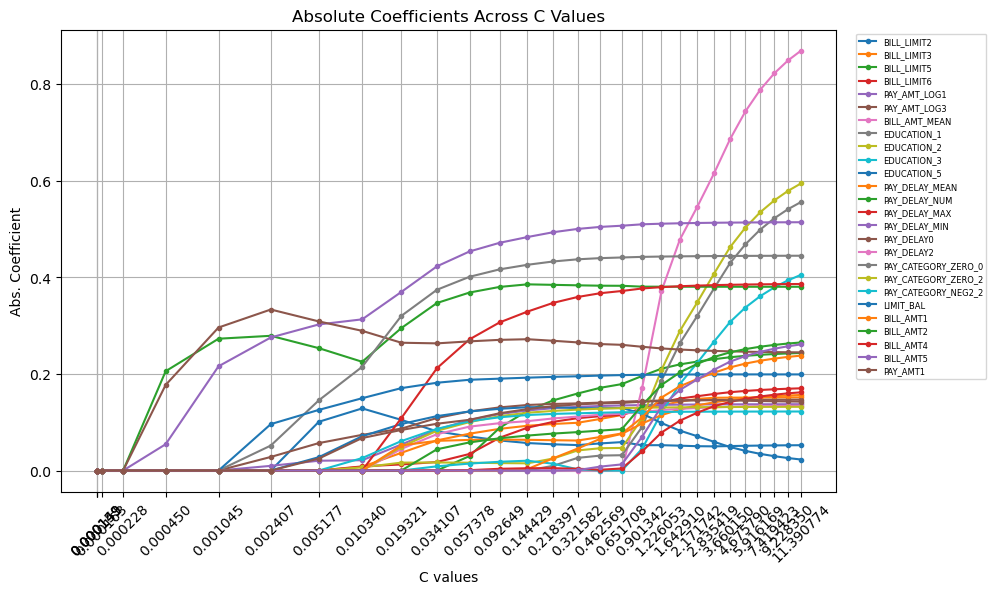

In [50]:
#Coefficient plot

plt.figure(figsize=(10,6))

for i in range(len(coefficients)):
        if np.abs(coefficients.iloc[i,:]).max() > 0.1:
            plt.plot(
                np.log10(coefficients.columns),
                np.abs(coefficients.iloc[i,:]),
                label=coefficients.index.values[i],
                marker='o',
                markersize = 3
            )

plt.xticks(
    np.log10(coefficients.columns),
    [f'{coef:.6f}' for coef in coefficients.columns],
    rotation = 45
)
plt.grid()
plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    fontsize=6
)
plt.title('Absolute Coefficients Across C Values')
plt.xlabel('C values')
plt.ylabel('Abs. Coefficient')
plt.show()

#### Number of Non-Zero Coefficients

We examine how the number of selected features changes with `C`. The x-axis uses a logarithmic scale to show the changes at small `C` values more clearly.

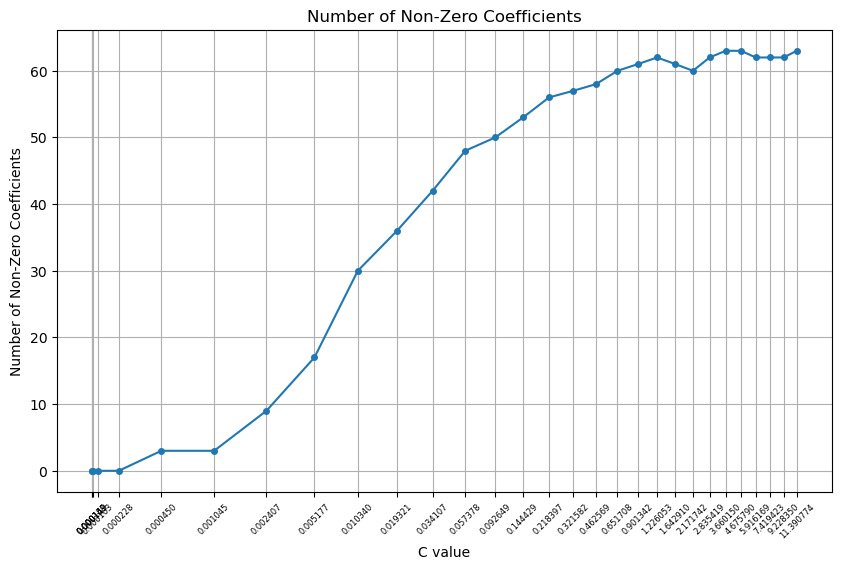

In [52]:

plt.figure(figsize=(10,6))
plt.plot(
    np.log(coefficients.columns),
    (coefficients != 0).sum(axis=0),
    marker = 'o',
    markersize = 4
)

plt.xticks(
    np.log(coefficients.columns),
    [f'{coef:.6f}' for coef in coefficients.columns],
    rotation = 45,
    fontsize = 6
)
plt.grid()
plt.title('Number of Non-Zero Coefficients')
plt.xlabel('C value')
plt.ylabel('Number of Non-Zero Coefficients')
plt.show()

### Selecting C Values for Cross-Validation

We select `C` values based on the number of non-zero coefficients. After selecting the first model with at least one non-zero coefficient, we select another `C` value whenever the feature count increases by at least six. This reduces the number of models to test while covering different feature counts.

In [54]:
n_nonzero = (coefficients != 0).sum(axis=0)

previous_limit = 0
c_values_to_test = []

for idx in n_nonzero.index:
    num_features = n_nonzero.loc[idx]
    if (num_features > previous_limit):
        previous_limit = num_features + 5  
        c_values_to_test.append(idx)
        
print(f'C values to be tested:')
for i,c in  enumerate(c_values_to_test,start=1):
    print(f'{i}: {c:.7f}')


C values to be tested:
1: 0.0004495
2: 0.0024066
3: 0.0051773
4: 0.0103399
5: 0.0193208
6: 0.0341073
7: 0.0573783
8: 0.2183970
9: 1.2260532


### Repeated Stratified Cross-Validation

Each selected `C` value is evaluated using 5-fold stratified cross-validation repeated five times. Stratification keeps similar class proportions in each fold, while repetition makes the comparison less dependent on a single split. All `C` values use the same splits, and features are standardized within each training fold. We compare the models using mean validation ROC AUC and report additional metrics.

In [56]:
binary_metrics_to_use = [
    ('Accuracy Score', accuracy_score, {}),
    ('Recall Score',recall_score,{'zero_division':0}),
    ('Precision Score', precision_score,{'zero_division':0}),
    ('F1 Score', f1_score, {'zero_division':0})
]

prob_metrics_to_use =[
    ('AUC ROC Score', roc_auc_score, {}),
    ('Average Precision', average_precision_score, {}),
    ('Brier Score loss', brier_score_loss, {})    
]

n_folds = 5
n_repeats = 5

repeated_skf = RepeatedStratifiedKFold(
    n_splits = n_folds,
    n_repeats = n_repeats,
    random_state = 42
)

splits = list(repeated_skf.split(X_train_all, y_train))

index_data = [(r,f,c) for r in range(n_repeats) for f in range(n_folds) for c in c_values_to_test]

rep_skf_result_file = '../Results/rep_skf_result.pkl'
rep_skf_result_path = Path(rep_skf_result_file)

if LOAD_TRAIN_RESULTS and rep_skf_result_path.exists():

    rep_skf_results = pd.read_pickle(rep_skf_result_file)
    print(f'Training results loaded from: {rep_skf_result_file}' )

else:

    multi_index = pd.MultiIndex.from_tuples(
        index_data,
        names=['Repeats', 'Folds','C']
        
    )
    
    rep_skf_results = pd.DataFrame(
        index = multi_index,
        columns = [
            'probabilities',
            'coefficients', 
            'intercept',
            'test_indices',
            'train_indices',
            'n_iter_',
            'training_proba',
            *[metric[0] for metric in binary_metrics_to_use], *[metric[0] for metric in prob_metrics_to_use]
        ],
        dtype = object
    )
    
    for i,(train_indices, test_indices) in enumerate(splits):
        fold = i % n_folds
        repeat = i // n_folds
    
        X_train_fold = X_train_all.iloc[train_indices][features_to_keep]
        y_train_fold = y_train.iloc[train_indices]
    
        
        X_test_fold = X_train_all.iloc[test_indices][features_to_keep]
        y_test_fold = y_train.iloc[test_indices]
        
        X_train_fold_scaled = scaler.fit_transform(X_train_fold)
        X_test_fold_scaled = scaler.transform(X_test_fold)
        
        for c in c_values_to_test:
    
            print(f'\x1b[2KModel traning - Repeat:{repeat} Fold:{fold} C:{c:<40}',end = '\r', flush = True)
        
            model = LogisticRegression(
                C=c,
                max_iter = 10000,
                l1_ratio = 1,
                penalty = 'elasticnet',
                solver = 'saga',
                random_state = 42
            )
        
            model.fit(X_train_fold_scaled,y_train_fold)
            training_proba = model.predict_proba(X_train_fold_scaled)[:,1]
            prob = model.predict_proba(X_test_fold_scaled)[:,1]
                
            rep_skf_results.at[
                (repeat,fold,c),
                'probabilities'
            ] = prob
    
            rep_skf_results.at[
                (repeat, fold, c),
                'coefficients'
            ] = model.coef_[0]
    
            rep_skf_results.at[
                (repeat, fold, c),
                'intercept'
            ] = model.intercept_
    
            rep_skf_results.at[
                (repeat, fold, c),
                'test_indices'
            ] = test_indices
    
            rep_skf_results.at[
                (repeat, fold, c),
                'train_indices'
            ] = train_indices
    
            rep_skf_results.at[
                (repeat, fold, c),
                'n_iter_'
            ] = model.n_iter_
    
            rep_skf_results.at[
                (repeat, fold, c),
                'training_proba'
            ] = training_proba
    
            pred = (prob >= 0.5).astype(int)
            
            for (metric_label, metric, kwarg) in binary_metrics_to_use:
                
                print(f'\x1b[2K{metric_label} calculation - Repeat:{repeat} Fold:{fold} - C:{c:<40}',end = '\r', flush = True)
                            
                score = metric(y_test_fold, pred, **kwarg)
                
                rep_skf_results.at[
                    (repeat, fold, c),
                    metric_label
                ] = score
              
            for (metric_label, metric, kwarg) in prob_metrics_to_use:
    
                print(f'\x1b[2K{metric_label} calculation - Repeat:{repeat} Fold:{fold} - C:{c:<40}',end = '\r', flush = True)
                
                score = metric(y_test_fold, prob, **kwarg)
                
                rep_skf_results.at[
                    (repeat, fold, c),
                    metric_label
                ] = score
            
    print(f'\r\x1b[2K------------------Training Finished-----------------')
    
    
    if not rep_skf_result_path.exists() or OVERWRITE_FILE:
        
        rep_skf_results.to_pickle(rep_skf_result_path)
        print(f'Training results saved to {rep_skf_result_file}')


Training results loaded from: ../Results/rep_skf_result.pkl


### Selecting C Based on Mean Validation ROC AUC

We select the `C` value with the highest mean validation ROC AUC across all folds and repeats. Other metrics are also plotted to compare model performance.

------------------------------------------
Accuracy Score - Maximum 0.821 at c=0.218397
Accuracy Score - Minimum 0.779 at c=0.000450


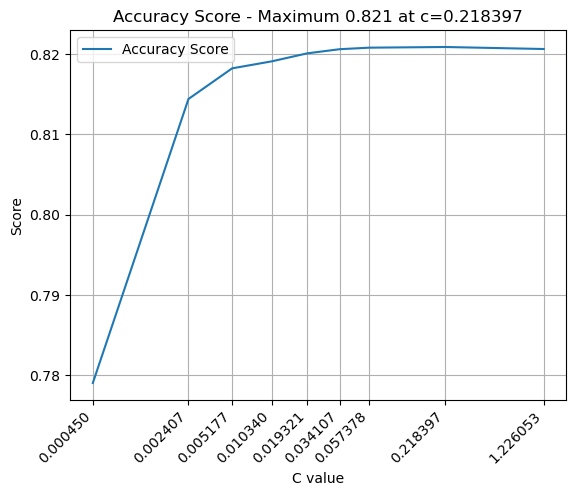

------------------------------------------
Recall Score - Maximum 0.362 at c=1.226053
Recall Score - Minimum 0.004 at c=0.000450


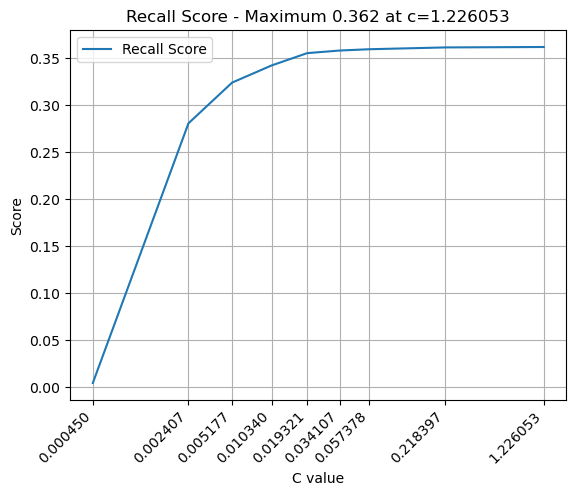

------------------------------------------
Precision Score - Maximum 0.701 at c=0.002407
Precision Score - Minimum 0.599 at c=0.000450


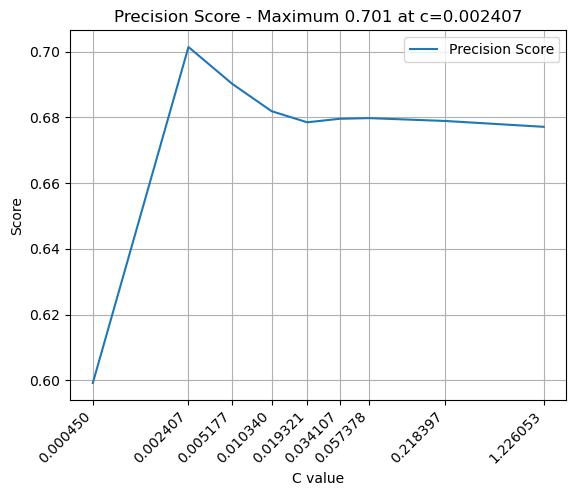

------------------------------------------
F1 Score - Maximum 0.472 at c=0.218397
F1 Score - Minimum 0.009 at c=0.000450


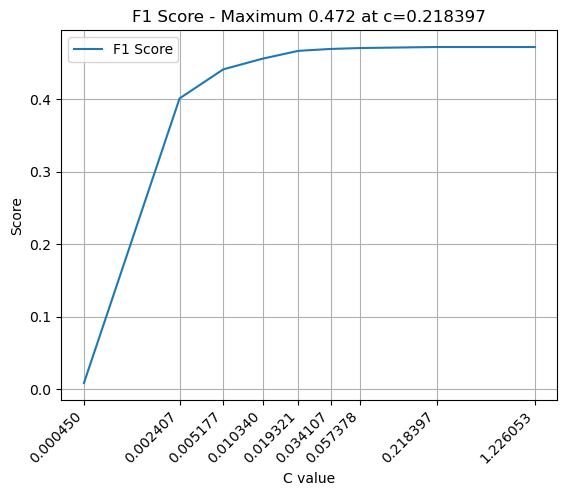

------------------------------------------
AUC ROC Score - Maximum 0.779 at c=0.05737827894384724
AUC ROC Score - Minimum 0.738 at c=0.00044952651982568294


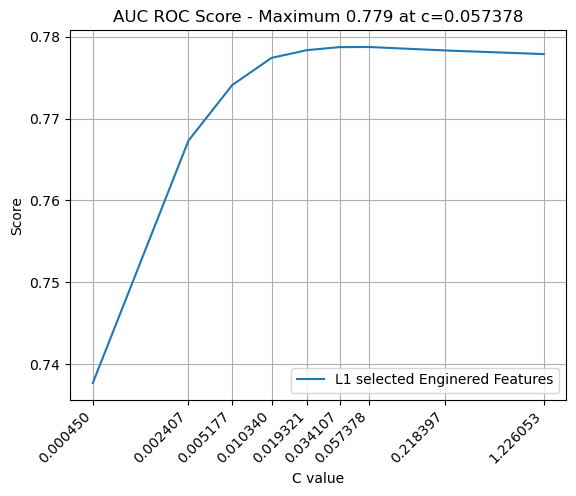

------------------------------------------
Average Precision - Maximum 0.543 at c=0.21839703129604646
Average Precision - Minimum 0.485 at c=0.00044952651982568294


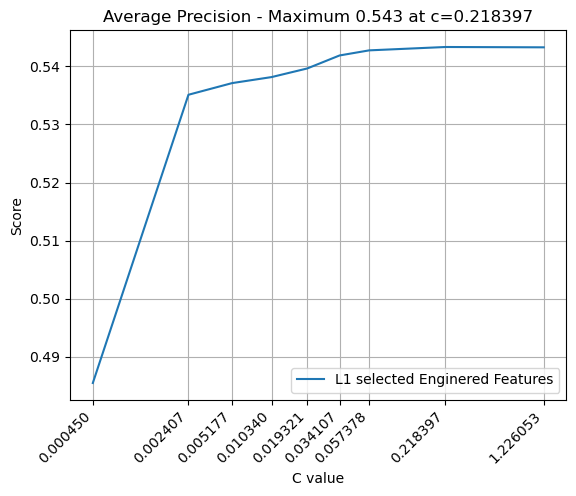

------------------------------------------
Brier Score loss - Maximum 0.156 at c=0.00044952651982568294
Brier Score loss - Minimum 0.135 at c=0.05737827894384724


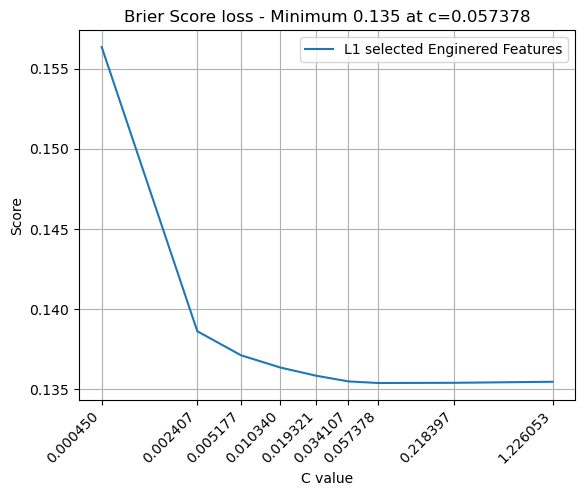

In [58]:
for (metric_label, metric, kwarg) in binary_metrics_to_use:

    metric_mean = rep_skf_results.groupby(by = 'C')[metric_label].mean()
    print('------------------------------------------')
    print(f'{metric_label} - Maximum {metric_mean.max():.3f} at c={metric_mean.index[metric_mean == metric_mean.max()][0]:.6f}')
    print(f'{metric_label} - Minimum {metric_mean.min():.3f} at c={metric_mean.index[metric_mean == metric_mean.min()][0]:.6f}')
    
    plt.plot(np.log(metric_mean.index),metric_mean, label = metric_label)
    plt.xticks(
        np.log(metric_mean.index),
        [f'{m:.6f}' for m in metric_mean.index],
        rotation = 45,
        ha = 'right'
    )
    plt.title(f'{metric_label} - Maximum {metric_mean.max():.3f} at c={metric_mean.index[metric_mean == metric_mean.max()][0]:.6f}')
    plt.xlabel('C value')
    plt.ylabel('Score')
    plt.legend()
    plt.grid()
    plt.show()
   

for (metric_label, metric, kwarg) in prob_metrics_to_use:
    
    metric_mean = rep_skf_results.groupby(by = 'C')[metric_label].mean()
        
    print('------------------------------------------')
    print(f'{metric_label} - Maximum {metric_mean.max():.3f} at c={metric_mean.index[metric_mean == metric_mean.max()][0]}')
    print(f'{metric_label} - Minimum {metric_mean.min():.3f} at c={metric_mean.index[metric_mean == metric_mean.min()][0]}')
        
    if metric_label == 'Brier Score loss':
        best_c = metric_mean.idxmin()
        best_label = 'Minimum'
        
    else:
        best_c = metric_mean.idxmax()
        best_label = 'Maximum'
    
    plt.plot(np.log(metric_mean.index),metric_mean, label = 'L1 selected Enginered Features')
    plt.xticks(
        np.log(metric_mean.index),
        [f'{m:.6f}' for m in metric_mean.index],
        rotation = 45,
        ha = 'right'
    )
    plt.title(f'{metric_label} - {best_label} {metric_mean.loc[best_c]:.3f} at c={best_c:.6f}')
    plt.xlabel('C value')
    plt.ylabel('Score')
    plt.legend()
    plt.grid()
    plt.show()

    if metric_label == 'AUC ROC Score':
        final_c = metric_mean.index[metric_mean == metric_mean.max()][0]
        
final_rep_skf_results = rep_skf_results.xs(
    final_c,
    level='C'
)


The highest mean validation ROC AUC was achieved at `C = 0.05737827894384724`. We select this value for the final L1 model and compare its performance with a baseline model trained using only the original features.

### Baseline Model

We train a baseline logistic regression model using only the original features, standardized within each training fold. We use the same folds as for the selected L1 model to compare their performance.

In [61]:
index_data_base = [(r,f) for r in range(n_repeats) for f in range(n_folds)]
 
rep_skf_results_base_file = '../Results/rep_skf_result_base.pkl'
rep_skf_results_base_path = Path(rep_skf_results_base_file)

if LOAD_TRAIN_RESULTS and rep_skf_results_base_path.exists():

    rep_skf_results_base = pd.read_pickle(rep_skf_results_base_file)
    print(f'Training result loaded from {rep_skf_results_base_file}')

else:  

    multi_index_base = pd.MultiIndex.from_tuples(
        index_data_base,
        names=['Repeats', 'Folds']
    )
        
    rep_skf_results_base = pd.DataFrame(
        index = multi_index_base,
        columns = [
            'probabilities',
            'coefficients', 
            'intercept',
            'test_indices',
            'train_indices',
            'n_iter_',
            'training_proba',
            *[metric[0] for metric in binary_metrics_to_use], *[metric[0] for metric in prob_metrics_to_use]
        ],
        dtype = object
    )
        
    for i,(train_indices, test_indices) in enumerate(splits):
        fold = i % n_folds
        repeat = i // n_folds
    
        X_train_fold = X_train.iloc[train_indices]
        y_train_fold = y_train.iloc[train_indices]
            
        X_test_fold = X_train.iloc[test_indices]
        y_test_fold = y_train.iloc[test_indices]
        
        X_train_fold_scaled = scaler.fit_transform(X_train_fold)
        X_test_fold_scaled = scaler.transform(X_test_fold)
        
    
        print(f'Model traning - Repeat:{repeat} Fold:{fold}',end = '\r', flush = True)
    
        model = LogisticRegression(
            max_iter = 10000,
            random_state = 42
        )
    
        model.fit(X_train_fold_scaled,y_train_fold)
        training_proba = model.predict_proba(X_train_fold_scaled)[:,1]
        prob = model.predict_proba(X_test_fold_scaled)[:,1]
        
        rep_skf_results_base.at[
            (repeat, fold),
            'probabilities'
        ] = prob
    
        rep_skf_results_base.at[
            (repeat, fold),
            'coefficients'
        ] = model.coef_[0]
    
        rep_skf_results_base.at[
            (repeat, fold),
            'intercept'
        ] = model.intercept_
    
        rep_skf_results_base.at[
            (repeat, fold),
            'test_indices'
        ] = test_indices
    
        rep_skf_results_base.at[
            (repeat, fold),
            'train_indices'
        ] = train_indices
    
        rep_skf_results_base.at[
            (repeat, fold),
            'n_iter_'
        ] = model.n_iter_
    
        rep_skf_results_base.at[
            (repeat, fold),
            'training_proba'
        ] = training_proba
    
        pred = (prob >= 0.5).astype(int)
        
        for (metric_label, metric, kwarg) in binary_metrics_to_use:
            
            print(f'{metric_label} calculation - Repeat:{repeat} Fold:{fold}',end = '\r', flush = True)
                        
            score = metric(y_test_fold, pred, **kwarg)
            
            rep_skf_results_base.at[
                (repeat, fold),
                metric_label
            ] = score
          
        for (metric_label, metric, kwarg) in prob_metrics_to_use:
    
            print(f'{metric_label} calculation - Repeat:{repeat} Fold:{fold}',end = '\r', flush = True)
            
            score = metric(y_test_fold, prob, **kwarg)
            
            rep_skf_results_base.at[
                (repeat, fold),
                metric_label
            ] = score    
    
    print(f'------------------Training Finished-----------------')

    if not rep_skf_results_base_path.exists() or OVERWRITE_FILE:
        rep_skf_results_base.to_pickle(rep_skf_results_base_path)
        print(f'Training result saved to {rep_skf_results_base_file}')



Training result loaded from ../Results/rep_skf_result_base.pkl


### Model Performance Comparison

We compare the mean validation metrics of the baseline and selected L1 models across all folds and repeats. Positive differences favor the selected model, except for Brier score, where lower values are better.

In [63]:
metric_names = [metric[0] for metric in binary_metrics_to_use + prob_metrics_to_use]

selected_model_metrics = rep_skf_results.xs(
    final_c,
    level = 'C',
)[metric_names].mean()

base_model_metrics = rep_skf_results_base[metric_names].mean()

metric_comparison = pd.DataFrame(
    {
        "Base Model": base_model_metrics,
        "Selected Model": selected_model_metrics,
        "Selected Minus Base": selected_model_metrics - base_model_metrics
        
    }
)

metric_comparison

,Base Model,Selected Model,Selected Minus Base
Accuracy Score,0.810992,0.820783,0.009792
Recall Score,0.245584,0.359503,0.113919
Precision Score,0.711409,0.679763,-0.031646
F1 Score,0.364924,0.470181,0.105258
AUC ROC Score,0.726174,0.778737,0.052563
Average Precision,0.505902,0.542768,0.036866
Brier Score loss,0.144513,0.135392,-0.009121


The selected model performs better than the baseline on all reported validation metrics except precision.

### Performance Comparison Across Folds

We compare ROC AUC and Brier score on each validation fold to see how consistently the selected model performs better than the baseline. We report the proportion of folds with higher ROC AUC and lower Brier score.

In [66]:
# Comparing AUC fold wise between base model and the selected model 
selected_model_auc = rep_skf_results.xs(
    final_c,
    level = 'C'
)['AUC ROC Score']

base_model_auc = rep_skf_results_base['AUC ROC Score']

auc_comparison = pd.DataFrame(
    {
        "Base Model AUC": base_model_auc,
        "Selected Model AUC": selected_model_auc,
        "Selected - Base AC": selected_model_auc - base_model_auc,
        "Selected AUC better": (selected_model_auc - base_model_auc) > 0
    }
)


# Comparing Brier Score Loss fold wise between base model and the selected model
selected_model_brier = rep_skf_results.xs(
    final_c,
    level = 'C'
)['Brier Score loss']

base_model_brier = rep_skf_results_base['Brier Score loss']

brier_comparison = pd.DataFrame(
    {
        "Base Model Brier": base_model_brier,
        "Selected Model Brier": selected_model_brier,
        "Selected - Base Brier": selected_model_brier - base_model_brier,
        "Selected Brier better": (selected_model_brier - base_model_brier) < 0
    }
)

print(f'Brier Score is better in folds with selected Model: {100*brier_comparison["Selected Brier better"].sum() / len(brier_comparison):.2f}%')
print(f'AUC is better in folds with selected Model: {100*auc_comparison["Selected AUC better"].sum() / len(auc_comparison):.2f}%')

Brier Score is better in folds with selected Model: 100.00%
AUC is better in folds with selected Model: 100.00%


The AUC score and the Brier Score Loss of the Selected model is better than the base model on every fold in every repeat, indicating a consistently better validation performance.

## Gradient Boosting Model

We train gradient boosting models on the same repeated folds as logistic regression to compare their performance. We test three learning rates and six maximum tree depths.

Each model can build up to 5,000 trees. Early stopping uses an internal validation set containing 10% of each training fold and stops training when validation loss does not improve sufficiently for 20 iterations.

In [129]:
max_depth = [1,2,3,4,5,6]
learning_rate = [0.1,0.05,0.03]

rep_skf_results_gb_file = '../Results/rep_skf_results_gb.pkl'
rep_skf_results_gb_path = Path(rep_skf_results_gb_file)

if LOAD_TRAIN_RESULTS and rep_skf_results_gb_path.exists():
    
    rep_skf_results_gb = pd.read_pickle(rep_skf_results_gb_file)
    print(f'Training result loaded from {rep_skf_results_gb_file}')

else:

    index_data_gb = [(r,f,depth,lr) for r in range(n_repeats) for f in range(n_folds) for depth in max_depth for lr in learning_rate]
    
    multi_index_gb = pd.MultiIndex.from_tuples(
        # index_data_gb,
        [],
        names=['Repeats', 'Folds', 'Depth', 'Learning Rate']
        
    )
    
    rep_skf_results_gb = pd.DataFrame(
        index = multi_index_gb,
        columns = [
            'probabilities',
            'feature_importances',
            'test_indices',
            'train_indices',
            'training_proba',
            'n_estimators',
            *[metric[0] for metric in binary_metrics_to_use], *[metric[0] for metric in prob_metrics_to_use]
        ],
        dtype = object
    )
    
for i,(train_indices, test_indices) in enumerate(splits):


    
    fold = i % n_folds
    repeat = i // n_folds

    X_train_fold = X_train_all[features_to_keep].iloc[train_indices]
    y_train_fold = y_train.iloc[train_indices]
        
    X_test_fold = X_train_all[features_to_keep].iloc[test_indices]
    y_test_fold = y_train.iloc[test_indices]
 
    for depth in max_depth:

        for lr in learning_rate:

            if ((repeat,fold,depth,lr) not in rep_skf_results_gb.index) or pd.isna(rep_skf_results_gb.at[(repeat,fold,depth,lr), 'Brier Score loss']):

                print(f'\r\x1b[2KModel Traning - Repeat:{repeat} Fold:{fold:} Depth:{depth} Learning Rate:{lr}',end = '', flush = True)
        
                gb_model = GradientBoostingClassifier(
                    learning_rate = lr,
                    max_depth = depth,
                    n_estimators = 5000,
                    n_iter_no_change = 20,
                    validation_fraction = 0.1, #Size of validation set for calculating the improvement (it is a stratified validation)
                    random_state = 42
                )
            
                gb_model.fit(X_train_fold,y_train_fold)
                training_proba = gb_model.predict_proba(X_train_fold)[:,1]
                prob = gb_model.predict_proba(X_test_fold)[:,1]

                rep_skf_results_gb.loc[(repeat,fold,depth,lr), :] = np.nan              
                
                rep_skf_results_gb.at[
                    (repeat,fold,depth,lr),
                    'probabilities'
                ] = prob
            
                rep_skf_results_gb.at[
                    (repeat,fold,depth,lr),
                    'feature_importances'
                    ] = gb_model.feature_importances_
    
                rep_skf_results_gb.at[
                    (repeat,fold,depth,lr),
                    'n_estimators'
                ] = gb_model.n_estimators_
            
                rep_skf_results_gb.at[
                    (repeat,fold,depth,lr),
                    'test_indices'
                ] = test_indices
            
                rep_skf_results_gb.at[
                    (repeat,fold,depth,lr),
                    'train_indices'
                ] = train_indices
            
            
                rep_skf_results_gb.at[
                    (repeat,fold,depth,lr),
                    'training_proba'
                ] = training_proba
            
                pred = (prob >= 0.5).astype(int)
                                
                for (metric_label, metric, kwarg) in binary_metrics_to_use:
                    
                    score = metric(y_test_fold, pred, **kwarg)
                    
                    rep_skf_results_gb.at[
                        (repeat,fold,depth,lr),
                        metric_label
                    ] = score
                  
                for (metric_label, metric, kwarg) in prob_metrics_to_use:
                                
                    score = metric(y_test_fold, prob, **kwarg)
                    
                    rep_skf_results_gb.at[
                        (repeat,fold,depth,lr),
                        metric_label
                    ] = score
                
                rep_skf_results_gb.to_pickle(rep_skf_results_gb_path)

            else:
                print(f'{(repeat,fold,depth,lr)} Loaded from {rep_skf_results_gb_path}'.ljust(100),end='\r', flush=True)
                    
print(f'\r\x1b[2K------------------Training Finished-----------------')

if not rep_skf_results_gb_path.exists() or OVERWRITE_FILE:
    rep_skf_results_gb.to_pickle(rep_skf_results_gb_path)
    print(f'Training result saved to {rep_skf_results_gb_file}')


Training result loaded from ../Results/rep_skf_results_gb.pkl
------------------Training Finished-----------------b.pkl                                       
Training result saved to ../Results/rep_skf_results_gb.pkl


#### Comparing Gradient Boosting Settings

We compare the mean validation ROC AUC, average precision, and Brier score for each learning rate and tree depth. The results are ranked by mean ROC AUC.

In [71]:
for idx in rep_skf_results_gb.index:
    y_proba_train = rep_skf_results_gb.at[idx,'training_proba']
    y_true_train = y_train.iloc[
        rep_skf_results_gb.at[idx,'train_indices']
    ]
    rep_skf_results_gb.at[
        idx,
        'train_brier_score'
        ] = brier_score_loss(y_true_train, y_proba_train)

metrics_gb = rep_skf_results_gb[['Accuracy Score', 'Recall Score',
       'Precision Score', 'F1 Score', 'AUC ROC Score', 'Average Precision',
       'Brier Score loss','train_brier_score']]

mean_metrics_gb = metrics_gb.groupby(
    level=['Learning Rate', 'Depth']
).mean()

mean_metrics_gb.sort_values(by='AUC ROC Score',ascending=False)[['AUC ROC Score', 'Average Precision',
       'Brier Score loss']] 


AUC ROC Score Average Precision Brier Score loss
Learning Rate Depth                                                 
0.05          4          0.786181          0.558188          0.13354
0.03          4          0.786172           0.55847         0.133508
0.05          5          0.786089          0.558725         0.133653
0.03          5          0.786004          0.558482         0.133631
0.05          3          0.785756          0.557093         0.133596
0.10          4          0.785722          0.556214         0.133667
0.03          3          0.785614          0.556457         0.133645
0.10          3          0.785391          0.555978         0.133693
              5          0.785233          0.556079         0.133995
0.03          6          0.785183          0.556559         0.133969
0.05          6          0.784974          0.555458         0.134134
              2          0.784501          0.551055         0.133994
0.10          2          0.784477          0.550704         0.134003
0.03          2          0.784326          0.551484         0.134005
0.10          6          0.783756          0.552754         0.134481
              1          0.782362          0.541815          0.13483
0.05          1          0.781899          0.541316         0.134885
0.03          1          0.781622          0.541374          0.13493

#### Training and Validation Loss

We compare mean training and validation Brier scores across tree depths to check for signs of overfitting.

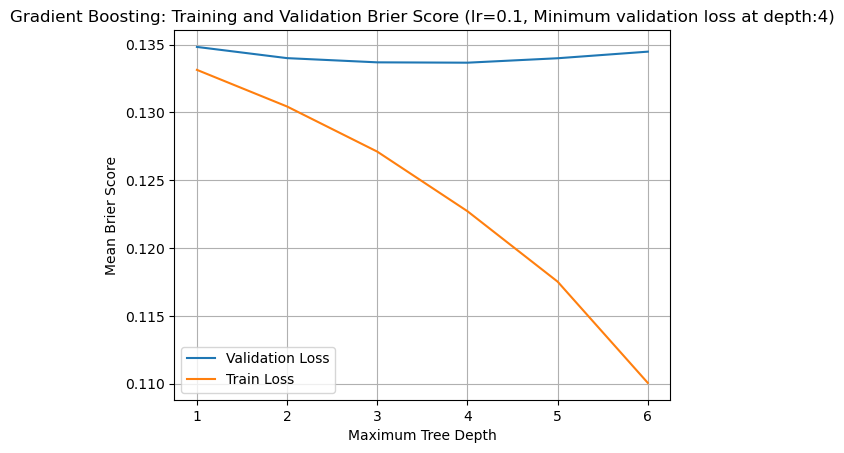

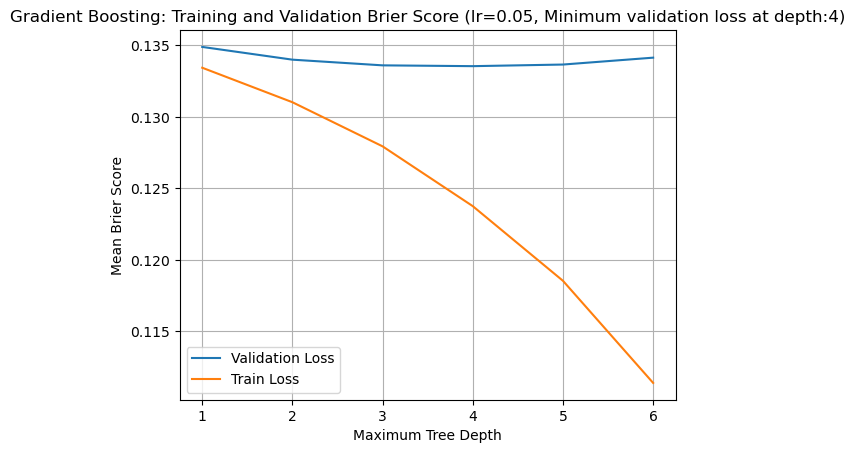

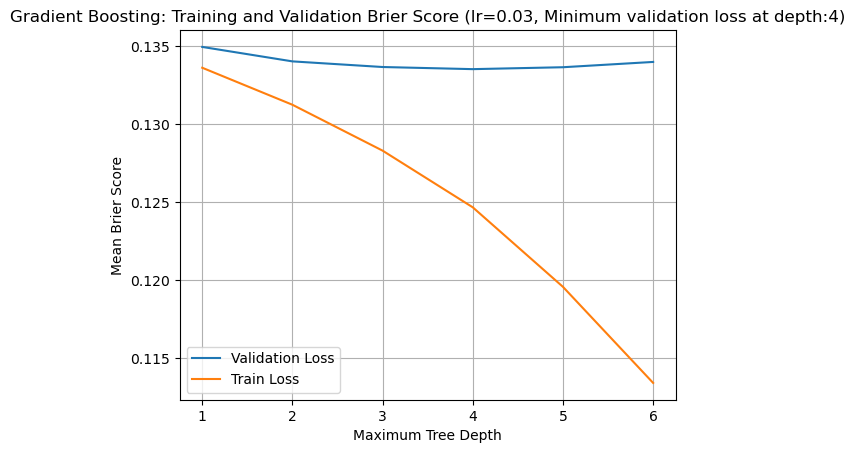

In [73]:
for lr in learning_rate:

    loss_val = mean_metrics_gb.xs(
        lr,
        level='Learning Rate'
    )['Brier Score loss']
    idx_val = loss_val.index
    

    plt.plot(idx_val, loss_val.loc[idx_val], label='Validation Loss')
    
    loss_train = mean_metrics_gb.xs(
        lr,
        level='Learning Rate'
    )['train_brier_score']
    idx_train = loss_train.index

    plt.plot(idx_train, loss_train.loc[idx_val], label='Train Loss')
    plt.legend()
    plt.grid()
    plt.title(f'Gradient Boosting: Training and Validation Brier Score (lr={lr}, Minimum validation loss at depth:{loss_val.idxmin()})')
    plt.xlabel('Maximum Tree Depth')
    plt.ylabel('Mean Brier Score')
    plt.show()

Training Brier score continues to decrease as tree depth increases, while validation Brier score is lowest at depth 4 for all three learning rates. This suggests overfitting at greater depths. We select depth 4 and a learning rate of 0.05 based on the highest mean validation ROC AUC, although its AUC is nearly identical to that of the model with a learning rate of 0.03.

In [75]:
best_gb = rep_skf_results_gb.xs(
    (0.05,4),
    level = ['Learning Rate', 'Depth']
)

print(f"n_estimators:\nMean: {best_gb['n_estimators'].mean():.3f}\nSTD: {best_gb['n_estimators'].std():.3f}\nMedian: {best_gb['n_estimators'].median()}")

n_estimators:
Mean: 130.240
STD: 32.902
Median: 129.0


Early stopping selects a different number of trees in each fold. We use the median of these values, 129, as `n_estimators` when training the final model on the full training set.

### Comparing Selected Models Across Folds

We report the proportion of validation folds where gradient boosting performs better than the selected logistic regression model. Lower values are better for Brier score; higher values are better for the other metrics.

In [78]:
all_metrics = [
        *[m[0] for m in binary_metrics_to_use],
        *[m[0] for m in prob_metrics_to_use]
]

best_gb_metrics = best_gb[all_metrics].to_numpy()

best_logreg_metrics = rep_skf_results.xs(
    final_c,
    level = 'C'
)[all_metrics].to_numpy()

gb_higher_rate = (best_gb_metrics > best_logreg_metrics).sum(axis=0) / len(best_gb_metrics)

print('Percentage of folds where Gradient Boosting has a higher metric value:')
for rate, metric in zip(gb_higher_rate, all_metrics):
    print(f'{metric:<25}{100 * rate} %')
    


Percentage of folds where Gradient Boosting has a higher metric value:
Accuracy Score           64.0 %
Recall Score             80.0 %
Precision Score          32.0 %
F1 Score                 76.0 %
AUC ROC Score            100.0 %
Average Precision        92.0 %
Brier Score loss         0.0 %


Gradient boosting achieves higher ROC AUC and lower Brier score on every validation fold. It also performs better on most folds for the other metrics, except precision. We now train both selected models on the full training set.

## Final Test Evaluation

Based on cross-validation results, we select gradient boosting as our final model. We train it on the full training set and evaluate it on the previously unused test set. We also train and evaluate the selected logistic regression model on the same data only for comparison.

In [81]:
# Training final models on the full training set and evaluating on the test set

model_gb = GradientBoostingClassifier(
    learning_rate = 0.05,
    max_depth = 4,
    n_estimators = 129,
    random_state = 42
)
X_train_all, _, _ = engineer_features(X_train)
X_test_all, _, _ = engineer_features(X_test)

model_gb.fit(X_train_all[features_to_keep],y_train)

prob_gb = model_gb.predict_proba(X_test_all[features_to_keep])[:,1]

model_lr = LogisticRegression(
    C = final_c,
    max_iter = 10000,
    l1_ratio = 1,
    penalty = 'elasticnet',
    solver = 'saga',
    random_state = 42
)


X_train_scaled = scaler.fit_transform(X_train_all[features_to_keep])
X_test_scaled = scaler.transform(X_test_all[features_to_keep])

model_lr.fit(X_train_scaled,y_train)

prob_lr = model_lr.predict_proba(X_test_scaled)[:,1]



In [82]:
# Comaparing metrics
final_results = pd.DataFrame(
    columns = metric_names,
    index = ['Gradient Boosting','Logistic Regression']
)

pred_lr = (prob_lr >= 0.5).astype(int)
pred_gb = (prob_gb >= 0.5).astype(int)

for (metric_label, metric, kwarg) in binary_metrics_to_use:
    
    score_lr = metric(y_test, pred_lr, **kwarg)
    score_gb = metric(y_test, pred_gb, **kwarg)

    final_results.at[
        'Logistic Regression',
        metric_label
    ] = score_lr
    
    final_results.at[
        'Gradient Boosting',
        metric_label
    ] = score_gb
  
for (metric_label, metric, kwarg) in prob_metrics_to_use:

    score_lr = metric(y_test, prob_lr, **kwarg)
    score_gb = metric(y_test, prob_gb, **kwarg)

    final_results.at[
        'Logistic Regression',
        metric_label
    ] = score_lr
    
    final_results.at[
        'Gradient Boosting',
        metric_label
    ] = score_gb

final_results

,Accuracy Score,Recall Score,Precision Score,F1 Score,AUC ROC Score,Average Precision,Brier Score loss
Gradient Boosting,0.818667,0.36624,0.663029,0.471845,0.782774,0.558386,0.134597
Logistic Regression,0.8185,0.362472,0.664365,0.469039,0.76935,0.530715,0.138194


Gradient boosting performs better than logistic regression on all reported test metrics except precision, where the difference is very small.

## Cost-Based Threshold Selection

The actual costs of false positives and false negatives are unknown. We set the false-positive cost to 1 unit and vary the false-negative cost from 0.01 to 20 units. For each cost ratio, we use the cross-validation predictions to find the threshold with the lowest average cost among the tested thresholds.

$$
\text{Cost} = FP + C_{FN} \times FN
$$

#### Prediction Outcomes Across Thresholds

We examine how the average numbers of true positives, false positives, true negatives, and false negatives change with the classification threshold.

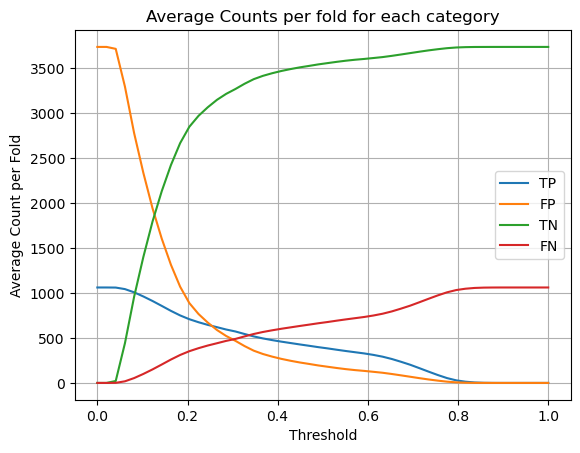

In [86]:

thresholds = np.linspace(0,1,50)
n_thresholds = len(thresholds)

prob_np = np.stack(
    best_gb['probabilities'].to_numpy()
).reshape(
    n_repeats,
    n_folds,
    1,
    -1
)


y_true_np = np.stack(
    [y_train.iloc[ind] for ind in best_gb['test_indices'].to_numpy()]
).reshape(
    n_repeats,
    n_folds,
    -1
)

y_true_mask = (y_true_np == 1)[:,:,None,:]

# print(f'y_true_mask shape: {y_true_mask.shape}')
# print(f'prob shape: {prob_np.shape}')

threshold_np = thresholds[None,None,:,None]
# print(f'threshold_np shape: {threshold_np.shape}')

pred_mask = prob_np >= threshold_np 
# print(f'pred_mask shape: {pred_mask.shape}')

TP_mask = pred_mask & y_true_mask
FP_mask = pred_mask & ~y_true_mask
TN_mask = ~pred_mask & ~y_true_mask
FN_mask = ~pred_mask & y_true_mask

confusion_count = np.stack(
    [
        TP_mask.sum(axis = 3),
        FP_mask.sum(axis = 3),
        TN_mask.sum(axis = 3),
        FN_mask.sum(axis = 3)
    ],
    axis = -1
)

multi_index_threshold_sweap = pd.MultiIndex.from_product(
    [[r for r in range(n_repeats)],[f for f in range(n_folds)],[t for t in thresholds]],
    names = ['Repeat', 'Fold', 'Threshold']
    
)

threshold_sweep = pd.DataFrame(
    confusion_count.reshape(-1,4),
    columns = ['TP','FP','TN','FN'],
    index = multi_index_threshold_sweap
)

mean = threshold_sweep.groupby(by='Threshold').mean()

for m in mean:
    plt.plot(mean.index,mean[m], label = m)

plt.xlabel('Threshold')
plt.ylabel('Average Count per Fold')
plt.title('Average Counts per fold for each category')
plt.legend()
plt.grid()
plt.show()


#### Cost Calculation and Threshold Selection

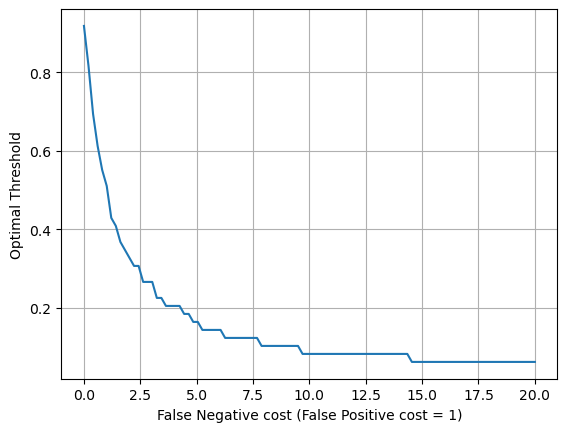

In [88]:
#Fixing FP cost as 1 unit we consider FN cost

n_costs = 100
fn_costs = np.linspace(0.01,20,n_costs)

threshold_sweep.index.levshape

fp_np = threshold_sweep[['FP']].to_numpy().reshape(n_repeats,n_folds,n_thresholds,-1)
fn_np = threshold_sweep[['FN']].to_numpy().reshape(n_repeats,n_folds,n_thresholds,-1)

costs_np = (fn_np[:,:,:,None,:] * fn_costs[None,None,None,:,None]) + fp_np[:,:,:,None,:]
costs_np.shape

multi_index_costs = pd.MultiIndex.from_product(
    [
        [r for r in range(n_repeats)],
        [f for f in range(n_folds)],
        [t for t in thresholds],
        [c for c in fn_costs]
    ],
    names=['Repeats','Folds','Thresholds','FN_costs']
)

costs = pd.DataFrame(
    costs_np.reshape(-1),
    index=multi_index_costs
)

# costs.groupby(by=['Thresholds','FN_costs']).mean().groupby(by='FN_costs').mean()

mean_cost = costs.groupby(by=['Thresholds','FN_costs']).mean()

threshold_for_min_cost = mean_cost.groupby(by='FN_costs').idxmin().map(lambda x: x[0])

plt.plot(threshold_for_min_cost.index,threshold_for_min_cost)

plt.xlabel('False Negative cost (False Positive cost = 1)')
plt.ylabel('Optimal Threshold')
plt.grid()
plt.show()


The plot shows which threshold gives the lowest average validation cost for each False Negative to False Positive cost ratio. As false negatives become more costly, the selected threshold decreases, reducing missed defaults at the expense of more false positives.

## Bootstrap Uncertainty Estimates

We use 10,000 bootstrap samples of the test set to estimate uncertainty in the final model's ROC AUC and Brier score. The model remains fixed, and the true labels and predicted probabilities are resampled together.

In [91]:
assert len(prob_gb) == len(y_test), 'Y_test and prob_gb have different length'

y_test_np = y_test.to_numpy()
n = len(prob_gb)
bootstrap_sample_count = 10000

auc_np = np.zeros([bootstrap_sample_count])
brier_np = np.zeros([bootstrap_sample_count])

rand_generator = np.random.RandomState(42)

for i in range(bootstrap_sample_count):
    
    y_resampled, prob_gb_resampled = resample(
        y_test_np,prob_gb,
        random_state = rand_generator,
        replace = True,
        n_samples = n
    )
    auc_np[i] = roc_auc_score(y_resampled, prob_gb_resampled)
    brier_np[i] = brier_score_loss(y_resampled, prob_gb_resampled)

lower, upper = np.percentile(auc_np, [2.5, 97.5])
print(
    f'ROC AUC: SE = {auc_np.std(ddof=1):.5f}, '
    f'95% bootstrap CI = [{lower:.5f}, {upper:.5f}]'
)

lower, upper = np.percentile(brier_np, [2.5, 97.5])
print(
    f'Brier score: SE = {brier_np.std(ddof=1):.5f}, '
    f'95% bootstrap CI = [{lower:.5f}, {upper:.5f}]'
)


ROC AUC: SE = 0.00751, 95% bootstrap CI = [0.76798, 0.79734]
Brier score: SE = 0.00295, 95% bootstrap CI = [0.12889, 0.14056]


The bootstrap results show limited variation in ROC AUC and Brier score across resampled test sets. This suggests that the reported test scores are reasonably stable with respect to test-sample variation.

## Conclusion

Feature engineering and L1 regularization improved logistic regression performance compared with the baseline. Gradient boosting achieved the highest mean validation ROC AUC and performed better than the selected logistic regression model on all reported test metrics except precision.

The cost analysis shows how the decision threshold can be adjusted to the relative costs of false positives and false negatives. Since the actual costs are unknown, there is no single threshold to recommend. The selected thresholds are based on cross-validation predictions; their cost performance has not been evaluated on the test set.